In [1]:
import pandas as pd
import numpy as numpy
import json
import gzip

# Checkpoint Three: Exploratory Analysis


## Section 1. Dataset profiles:

## Section 2. Anomalies:

## Section 3. Distributions:

## Section 4. Relationships:
### Relationship Plot 1: Review characteristics and restaurant closure status

This section explores the question: **How do average rating and review volume jointly relate to whether a Chicago restaurant is marked permanently closed?**

The unit of analysis in this plot is one restaurant. Review count is also used as an indicator for establishment popularity because the Google metadata provides a status at the time when the dataset snapshot was taken but no closure date. For this reason this is a descriptive association rather than evidence that reviews cause or predict an establisments closure.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None)

# This works whether the notebook is launched from the repository root
# or from inside EDA_Checkpoint/.
data_candidates = [
    Path("data/meta-Illinois.json.gz"),
    Path("../data/meta-Illinois.json.gz"),
]
google_metadata_path = next(
    (path for path in data_candidates if path.exists()),
    None,
)

if google_metadata_path is None:
    raise FileNotFoundError(
        "Could not find data/meta-Illinois.json.gz. "
        "Place the UCSD Google Local metadata file in the repository's data folder."
    )

print(f"Using metadata file: {google_metadata_path.resolve()}")

Using metadata file: G:\My Drive\CS-418 Economics Group\Project_repo\CS418_Economic_Trajectories_Group\data\meta-Illinois.json.gz


In [3]:
google_metadata = pd.read_json(
    google_metadata_path,
    lines=True,
    compression="gzip",
)

print(f"Google Illinois metadata shape: {google_metadata.shape}")

Google Illinois metadata shape: (179205, 15)


### Preparation and status definition

Restaurants are identified when at least one Google category contains the word restaurant. Chicago records are identified from the city and state portion of the address. 

Duplicate gmap_id values are removed so that every business appears once.

For the outcome, **Permanently closed** is compared with nonmissing status strings that describe operating hours, such as "Open - Closes 10PM" or "Closed - Opens 11AM". Records marked **Temporarily closed** and records with missing status are excluded because they don't provide a defensible open vs. permanently-closed classification.

In [4]:
def has_restaurant_category(categories):
    return isinstance(categories, list) and any(
        "restaurant" in str(category).lower()
        for category in categories
    )

is_restaurant = google_metadata["category"].apply(has_restaurant_category)
is_chicago = google_metadata["address"].str.contains(
    r",\s*Chicago,\s*IL\b",
    case=False,
    na=False,
    regex=True,
)

chicago_restaurants = google_metadata.loc[
    is_restaurant & is_chicago
].copy()

duplicate_gmap_ids = int(chicago_restaurants.duplicated("gmap_id").sum())
chicago_restaurants = chicago_restaurants.drop_duplicates(
    subset="gmap_id",
    keep="first",
).copy()

status = chicago_restaurants["state"].astype("string").str.strip()
is_permanently_closed = status.str.casefold().eq("permanently closed").fillna(False)
is_temporarily_closed = status.str.contains(
    "temporarily closed", case=False, na=False
)
is_missing_status = status.isna() | status.eq("")
is_observed_operating = ~(
    is_permanently_closed | is_temporarily_closed | is_missing_status
)

chicago_restaurants["status_group"] = np.select(
    [
        is_permanently_closed,
        is_temporarily_closed,
        is_missing_status,
        is_observed_operating,
    ],
    [
        "Permanently closed",
        "Temporarily closed",
        "Missing status",
        "Observed operating",
    ],
    default="Unclassified",
)

status_order = [
    "Observed operating",
    "Permanently closed",
    "Temporarily closed",
    "Missing status",
]
status_audit = (
    chicago_restaurants["status_group"]
    .value_counts()
    .reindex(status_order, fill_value=0)
    .rename_axis("status_group")
    .reset_index(name="restaurants")
)

print(f"Chicago restaurant records before ID deduplication: {int((is_restaurant & is_chicago).sum()):,}")
print(f"Duplicate gmap_id rows removed: {duplicate_gmap_ids:,}")
print(f"Unique Chicago restaurants: {len(chicago_restaurants):,}")
display(status_audit)

Chicago restaurant records before ID deduplication: 8,043
Duplicate gmap_id rows removed: 9
Unique Chicago restaurants: 8,034


,status_group,restaurants
0,Observed operating,3989
1,Permanently closed,1440
2,Temporarily closed,292
3,Missing status,2313


In [5]:
analysis_restaurants = chicago_restaurants.loc[
    chicago_restaurants["status_group"].isin(
        ["Observed operating", "Permanently closed"]
    ),
    [
        "gmap_id",
        "name",
        "address",
        "avg_rating",
        "num_of_reviews",
        "status_group",
    ],
].copy()
analysis_restaurants["permanently_closed"] = (
    analysis_restaurants["status_group"] == "Permanently closed"
).astype(int)

assert not analysis_restaurants["gmap_id"].duplicated().any()
assert analysis_restaurants[["avg_rating", "num_of_reviews"]].notna().all().all()
assert analysis_restaurants["avg_rating"].between(1, 5).all()
assert analysis_restaurants["num_of_reviews"].gt(0).all()

sample_audit = pd.DataFrame(
    {
        "measure": [
            "Restaurants in analysis",
            "Observed operating",
            "Permanently closed",
            "Overall permanently closed percentage",
        ],
        "value": [
            f"{len(analysis_restaurants):,}",
            f"{(analysis_restaurants['status_group'] == 'Observed operating').sum():,}",
            f"{analysis_restaurants['permanently_closed'].sum():,}",
            f"{analysis_restaurants['permanently_closed'].mean():.1%}",
        ],
    }
)
display(sample_audit)

,measure,value
0,Restaurants in analysis,"5,429"
1,Observed operating,"3,989"
2,Permanently closed,"1,440"
3,Overall permanently closed percentage,26.5%


### Relationship: rating, review volume, and permanent closure

Review count is divided into quartiles so that each row of the heatmap has a substantial number of restaurants despite the strong right skew in review volume. Ratings are grouped into half-star-width bands. Each cell reports both the percentage marked permanently closed and the number of restaurants used to calculate that percentage. Very small cells should be interpreted cautiously.

In [6]:
rating_labels = ["<3.0", "3.0-3.4", "3.5-3.9", "4.0-4.4", "4.5-5.0"]
analysis_restaurants["rating_band"] = pd.cut(
    analysis_restaurants["avg_rating"],
    bins=[-np.inf, 3.0, 3.5, 4.0, 4.5, np.inf],
    labels=rating_labels,
    right=False,
)

quartile_labels = ["Q1", "Q2", "Q3", "Q4"]
analysis_restaurants["review_volume_quartile"] = pd.qcut(
    analysis_restaurants["num_of_reviews"],
    q=4,
    labels=quartile_labels,
)

quartile_ranges = (
    analysis_restaurants.groupby("review_volume_quartile", observed=True)["num_of_reviews"]
    .agg(minimum="min", maximum="max", restaurants="size", median="median")
)
quartile_ranges.index.name = "review-volume quartile"
display(quartile_ranges)

cell_summary = (
    analysis_restaurants.groupby(
        ["review_volume_quartile", "rating_band"],
        observed=False,
    )["permanently_closed"]
    .agg(closure_rate="mean", restaurants="size")
    .reset_index()
)

closure_rate = (
    cell_summary.pivot(
        index="review_volume_quartile",
        columns="rating_band",
        values="closure_rate",
    )
    .reindex(index=quartile_labels, columns=rating_labels)
    * 100
)
cell_counts = (
    cell_summary.pivot(
        index="review_volume_quartile",
        columns="rating_band",
        values="restaurants",
    )
    .reindex(index=quartile_labels, columns=rating_labels)
    .fillna(0)
    .astype(int)
)

annotations = closure_rate.copy().astype(object)
for row in closure_rate.index:
    for column in closure_rate.columns:
        rate = closure_rate.loc[row, column]
        count = cell_counts.loc[row, column]
        annotations.loc[row, column] = (
            f"{rate:.1f}%\n(n={count:,})" if count else "No data"
        )

quartile_closure = (
    analysis_restaurants.groupby("review_volume_quartile", observed=True)["permanently_closed"]
    .agg(restaurants="size", permanently_closed_percentage=lambda values: 100 * values.mean())
)
quartile_closure["permanently_closed_percentage"] = (
    quartile_closure["permanently_closed_percentage"].round(1)
)
display(quartile_closure)

,minimum,maximum,restaurants,median
review-volume quartile,,,,
Q1,1,46,1376,18.0
Q2,47,119,1339,77.0
Q3,121,298,1394,192.5
Q4,302,9998,1320,518.0


,restaurants,permanently_closed_percentage
review_volume_quartile,,
Q1,1376,52.0
Q2,1339,31.1
Q3,1394,15.5
Q4,1320,7.0


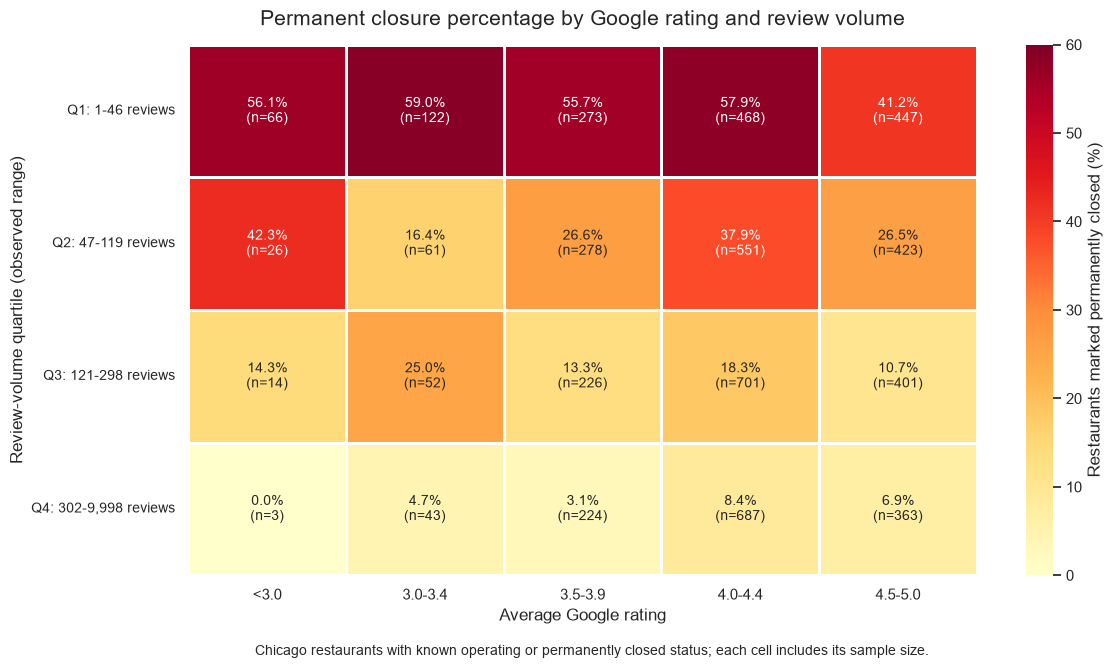

In [7]:
quartile_axis_labels = [
    f"{quartile}: {int(quartile_ranges.loc[quartile, 'minimum']):,}-"
    f"{int(quartile_ranges.loc[quartile, 'maximum']):,} reviews"
    for quartile in quartile_labels
]

fig, ax = plt.subplots(figsize=(12, 6.5))
sns.heatmap(
    closure_rate,
    annot=annotations,
    fmt="",
    cmap="YlOrRd",
    vmin=0,
    vmax=60,
    linewidths=1,
    linecolor="white",
    cbar_kws={"label": "Restaurants marked permanently closed (%)"},
    annot_kws={"fontsize": 10},
    ax=ax,
)
ax.set_title(
    "Permanent closure percentage by Google rating and review volume",
    fontsize=15,
    pad=14,
)
ax.set_xlabel("Average Google rating", fontsize=12)
ax.set_ylabel("Review-volume quartile (observed range)", fontsize=12)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0, fontsize=11)
ax.set_yticklabels(quartile_axis_labels, rotation=0, fontsize=10)
fig.text(
    0.5,
    -0.02,
    "Chicago restaurants with known operating or permanently closed status; each cell includes its sample size.",
    ha="center",
    fontsize=10,
)
plt.tight_layout()
plt.show()

#### Supplementary summary: review volume and permanent closure

The heatmap indicated nicely that review volume has the cleanest relationship with closure status. For this reason including a supplementary bar graph showing this relationship felt neccessary to make the overall pattern easier to compare. 

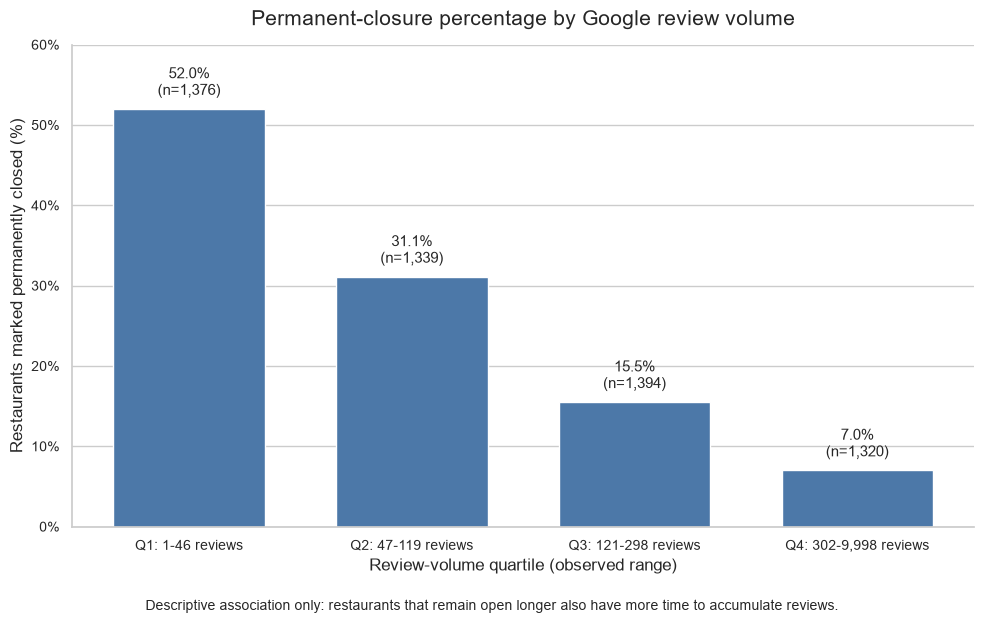

In [8]:
bar_data = quartile_closure.reset_index().copy()
bar_data["quartile_label"] = quartile_axis_labels

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(
    bar_data["quartile_label"],
    bar_data["permanently_closed_percentage"],
    color="#4C78A8",
    width=0.68,
)

for bar, percentage, count in zip(
    bars,
    bar_data["permanently_closed_percentage"],
    bar_data["restaurants"],
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1.2,
        f"{percentage:.1f}%\n(n={int(count):,})",
        ha="center",
        va="bottom",
        fontsize=11,
    )

ax.set_title(
    "Permanent-closure percentage by Google review volume",
    fontsize=15,
    pad=14,
)
ax.set_xlabel("Review-volume quartile (observed range)", fontsize=12)
ax.set_ylabel("Restaurants marked permanently closed (%)", fontsize=12)
ax.set_ylim(0, 60)
ax.set_yticks(np.arange(0, 61, 10))
ax.set_yticklabels([f"{value}%" for value in range(0, 61, 10)])
ax.tick_params(axis="x", labelsize=10)
ax.tick_params(axis="y", labelsize=10)
ax.grid(axis="x", visible=False)
sns.despine(ax=ax)
fig.text(
    0.5,
    -0.03,
    "Descriptive association only: restaurants that remain open longer also have more time to accumulate reviews.",
    ha="center",
    fontsize=10,
)
plt.tight_layout()
plt.show()

### So what?

The clearest relationship is the review volume. Since we divided the review volumes into quartiles Q1, Q2, Q3, and Q4. Q1 were marked **52.0%** closed. Meaning that of the restaurants that had between 1-46 reviews on Google more than half had permenantly closed. Now compare that with only **7.0%** in Q4 (302-9,998 reviews). Moreover, restaurants with lower ratings had a closure rate. Overall: **45.9%** of restaurants rated below 3.0 out if 5.0 were marked permanently closed, compared with **22.3%** of restaurants rated 4.5-5.0. However, the rating pattern is less consistent within individual review-volume quartiles, and some low-rating cells have small sample sizes.

This relationship very important beacuse it suggest that review volume or amount is our proxy for popularity. And it may carry a stronger and more accurate relationship with operating status than average ratings alone.

This direction was expected because restaurants with more customer activity online should generally be more likely to keep their doors open. The size of the difference between Q1, lowest, and Q4, highest, review-volumes was more pronounced than we expected.

However, these results shouldn't be interpreted as a validated prediction on how an establishment will fare. Restraurants that remain open longer also have more time to accumlate reviews. Meaning, that businesses that have been established for a long time or exposure due to things like, franchises, may explain this pattern.

Google provides a snapshot status rather than a closure date, and businesses with missing or temporary status were excluded. A later predictive analysis would need time-indexed review features, a known outcome date, and controls for restaurant age, location, price, and category.

## Relationship Plot 2: Negative Google ratings and subsequent food inspection results

This section explores the question: **Do Chicago restaurants with worse food-inspection outcomes have a higher share of negative Google ratings beforehand?**

The second plot will compare primary Google Local Reviews data to the secondary Chicago Food Inspections dataset. To keep temporal order, review characteristics are calculated only from a year or 365 days before an inspection. One and two star ratings are classified as negative. Each restaurant contributes only its first qualifying inspection, and at least five years of ratings history are required.

In [9]:
import difflib
import io
import re
import time
import unicodedata
import urllib.parse
import urllib.request
from collections import defaultdict

review_candidates = [
    Path("data/review-Illinois.json.gz"),
    Path("../data/review-Illinois.json.gz"),
]
google_reviews_path = next(
    (path for path in review_candidates if path.exists()),
    None,
)
if google_reviews_path is None:
    raise FileNotFoundError(
        "Could not find data/review-Illinois.json.gz. "
        "Place the UCSD Google Local review file in the repository's data folder."
    )

inspection_endpoint = "https://data.cityofchicago.org/resource/4ijn-s7e5.csv"
dollar = chr(36)
inspection_parameters = {
    dollar + "select": (
        "inspection_id,dba_name,address,inspection_date,results,latitude,longitude"
    ),
    dollar + "where": (
        "inspection_date between '2018-01-01T00:00:00' and '2021-12-31T23:59:59' "
        "AND facility_type='Restaurant' "
        "AND results in('Pass','Pass w/ Conditions','Fail')"
    ),
    dollar + "order": "inspection_date ASC, inspection_id ASC",
    dollar + "limit": "50000",
}
inspection_url = inspection_endpoint + "?" + urllib.parse.urlencode(
    inspection_parameters
)

last_error = None
for attempt in range(3):
    try:
        with urllib.request.urlopen(inspection_url, timeout=120) as response:
            food_inspections_historical = pd.read_csv(io.BytesIO(response.read()))
        break
    except Exception as error:
        last_error = error
        if attempt == 2:
            raise
        time.sleep(2 ** attempt)

if len(food_inspections_historical) >= 50000:
    raise RuntimeError(
        "The inspection query reached its 50,000-row limit; pagination is required."
    )

food_inspections_historical["inspection_date"] = pd.to_datetime(
    food_inspections_historical["inspection_date"],
    errors="coerce",
)
food_inspections_historical = food_inspections_historical.dropna(
    subset=["inspection_date", "latitude", "longitude", "dba_name"]
).copy()
food_inspections_historical = food_inspections_historical.loc[
    food_inspections_historical["latitude"].between(41.60, 42.10)
    & food_inspections_historical["longitude"].between(-87.95, -87.50)
].copy()

print(f"Historical restaurant inspections retrieved: {len(food_inspections_historical):,}")
print(
    "Inspection date range:",
    food_inspections_historical["inspection_date"].min().date(),
    "to",
    food_inspections_historical["inspection_date"].max().date(),
)
display(
    food_inspections_historical["results"]
    .value_counts()
    .rename_axis("inspection result")
    .reset_index(name="inspections")
)

Historical restaurant inspections retrieved: 38,360
Inspection date range: 2018-01-02 to 2021-12-30


,inspection result,inspections
0,Pass,15351
1,Pass w/ Conditions,14563
2,Fail,8446


### Restaurant linkage

This potential linkage error has to be mentioned. Since these two datasets dont share a common business ID, restraurants are therefore generated from neighboring latitude and longitude grid cells and found using exact geograpic data and business name and street number used as a backup ID. This is the reason for the extra code below.

A match is only accepted when either name similarity is at least 0.80 within 60 meters, or the street number agrees within 40 meters and the names have some moderate similarity. This allows for only the best candidate being retained for each inspection reducing false matches while allowing things like abbreviations.

In [10]:
def normalize_business_name(value):
    normalized = (
        unicodedata.normalize("NFKD", str(value))
        .encode("ascii", "ignore")
        .decode()
    )
    normalized = re.sub(r"[^a-z0-9 ]+", " ", normalized.lower())
    normalized = re.sub(
        r"\b(inc|llc|corp|corporation|company|co|restaurant|restaurants|the)\b",
        " ",
        normalized,
    )
    return " ".join(normalized.split())


def extract_street_number(value):
    match = re.search(r"\b(\d+)\b", str(value))
    return match.group(1) if match else None


def haversine_distance_m(lat1, lon1, lat2, lon2):
    radius_m = 6_371_000.0
    phi1 = np.radians(lat1)
    phi2 = np.radians(lat2)
    delta_phi = np.radians(lat2 - lat1)
    delta_lambda = np.radians(lon2 - lon1)
    haversine = (
        np.sin(delta_phi / 2) ** 2
        + np.cos(phi1) * np.cos(phi2) * np.sin(delta_lambda / 2) ** 2
    )
    return 2 * radius_m * np.arcsin(np.sqrt(haversine))


google_match_table = chicago_restaurants[
    ["gmap_id", "name", "address", "latitude", "longitude"]
].dropna(subset=["latitude", "longitude"]).copy()
google_match_table["normalized_name"] = google_match_table["name"].map(
    normalize_business_name
)
google_match_table["street_number"] = google_match_table["address"].map(
    extract_street_number
)
google_match_table["grid_lat"] = np.floor(
    google_match_table["latitude"] * 1000
).astype(int)
google_match_table["grid_lon"] = np.floor(
    google_match_table["longitude"] * 1000
).astype(int)

inspection_match_table = food_inspections_historical.copy()
inspection_match_table["normalized_name"] = inspection_match_table["dba_name"].map(
    normalize_business_name
)
inspection_match_table["street_number"] = inspection_match_table["address"].map(
    extract_street_number
)
inspection_match_table["grid_lat"] = np.floor(
    inspection_match_table["latitude"] * 1000
).astype(int)
inspection_match_table["grid_lon"] = np.floor(
    inspection_match_table["longitude"] * 1000
).astype(int)

spatial_grid = defaultdict(list)
for google_index, google_row in google_match_table.iterrows():
    spatial_grid[(google_row.grid_lat, google_row.grid_lon)].append(google_index)

candidate_matches = []
for inspection in inspection_match_table.itertuples(index=False):
    candidate_indices = []
    for latitude_offset in (-1, 0, 1):
        for longitude_offset in (-1, 0, 1):
            candidate_indices.extend(
                spatial_grid.get(
                    (
                        inspection.grid_lat + latitude_offset,
                        inspection.grid_lon + longitude_offset,
                    ),
                    [],
                )
            )
    if not candidate_indices:
        continue

    nearby_google = google_match_table.loc[candidate_indices]
    distances = haversine_distance_m(
        inspection.latitude,
        inspection.longitude,
        nearby_google["latitude"].to_numpy(),
        nearby_google["longitude"].to_numpy(),
    )

    for google_index, distance_m in zip(nearby_google.index, distances):
        if distance_m > 60:
            continue
        google_candidate = google_match_table.loc[google_index]
        name_similarity = difflib.SequenceMatcher(
            None,
            inspection.normalized_name,
            google_candidate.normalized_name,
        ).ratio()
        same_street_number = bool(
            inspection.street_number
            and google_candidate.street_number
            and inspection.street_number == google_candidate.street_number
        )
        name_containment = bool(
            min(
                len(inspection.normalized_name),
                len(google_candidate.normalized_name),
            )
            >= 4
            and (
                inspection.normalized_name in google_candidate.normalized_name
                or google_candidate.normalized_name in inspection.normalized_name
            )
        )
        strong_name_match = name_similarity >= 0.80 and distance_m <= 60
        address_supported_match = (
            distance_m <= 40
            and same_street_number
            and (name_similarity >= 0.55 or name_containment)
        )
        if strong_name_match or address_supported_match:
            candidate_matches.append(
                {
                    "inspection_id": inspection.inspection_id,
                    "inspection_name": inspection.dba_name,
                    "inspection_date": inspection.inspection_date,
                    "results": inspection.results,
                    "gmap_id": google_candidate.gmap_id,
                    "google_name": google_candidate["name"],
                    "distance_m": float(distance_m),
                    "name_similarity": name_similarity,
                    "match_score": name_similarity - float(distance_m) / 1000,
                }
            )

matched_inspections = pd.DataFrame(candidate_matches)
matched_inspections = (
    matched_inspections.sort_values(
        ["inspection_id", "match_score"],
        ascending=[True, False],
    )
    .drop_duplicates("inspection_id")
    .reset_index(drop=True)
)

match_audit = pd.DataFrame(
    {
        "measure": [
            "Historical inspections retrieved",
            "Inspections linked to Google restaurants",
            "Unique linked Google restaurants",
            "Median link distance (meters)",
            "Median name similarity",
        ],
        "value": [
            f"{len(food_inspections_historical):,}",
            f"{len(matched_inspections):,}",
            f"{matched_inspections['gmap_id'].nunique():,}",
            f"{matched_inspections['distance_m'].median():.1f}",
            f"{matched_inspections['name_similarity'].median():.2f}",
        ],
    }
)
display(match_audit)
display(
    matched_inspections.sample(8, random_state=418)[
        [
            "inspection_name",
            "google_name",
            "distance_m",
            "name_similarity",
            "results",
        ]
    ].round({"distance_m": 1, "name_similarity": 2})
)

,measure,value
0,Historical inspections retrieved,"38,360"
1,Inspections linked to Google restaurants,"22,831"
2,Unique linked Google restaurants,"5,182"
3,Median link distance (meters),13.9
4,Median name similarity,1.00


,inspection_name,google_name,distance_m,name_similarity,results
2802,EL POLLO REAL,El Pollo Real,7.3,1.00,Pass w/ Conditions
471,DE ARCOS PIZZA & RESTAURANT,De Arcos Pizza,16.2,1.00,Fail
19788,El Gran Burrito Express,El Gran Burrito Express,14.2,1.00,Pass w/ Conditions
453,SARPINOS PIZZERIA,Sarpino's Pizzeria,16.9,0.97,Fail
16512,TACO BELL,Taco Bell,35.5,1.00,Pass w/ Conditions
12183,CELESTE,Celeste,4.1,1.00,Pass
10785,EL ALEGRE BURRITO,El Alegre Burrito (Chicago),16.7,0.81,Pass w/ Conditions
6621,TAQUERIA EL CHARRO,Taquería El Charro I,16.5,0.95,Pass w/ Conditions


### Constructing prior-review features

The Illinois review archive is streamed rather than loaded fully into memory. Only ratings and timestamps that can be linked to Chicago restaurants are retained. For every inspection, the negative reviews shared is calculated from ratings posted with in the 365 days. Datapoints with fewer than five ratings are removed. Also earliest inspection is selected for each restaurant so that businesses that get more inspections in the same amount of time due to their type (seafood restraunts) dont saturate the comparison.

In [11]:
target_gmap_ids = set(matched_inspections["gmap_id"])
reviews_by_business = defaultdict(list)
total_review_rows = 0
retained_review_rows = 0
scan_started = time.time()

with gzip.open(google_reviews_path, "rt", encoding="utf-8") as review_file:
    for line in review_file:
        total_review_rows += 1
        review = json.loads(line)
        gmap_id = review.get("gmap_id")
        if gmap_id in target_gmap_ids:
            rating = review.get("rating")
            timestamp = review.get("time")
            if isinstance(rating, (int, float)) and isinstance(timestamp, (int, float)):
                reviews_by_business[gmap_id].append(
                    (int(timestamp), float(rating))
                )
                retained_review_rows += 1
        if total_review_rows % 5_000_000 == 0:
            print(
                f"Scanned {total_review_rows:,} reviews; "
                f"retained {retained_review_rows:,}."
            )

review_arrays = {}
for gmap_id, values in reviews_by_business.items():
    values.sort(key=lambda item: item[0])
    review_arrays[gmap_id] = (
        np.array([item[0] for item in values], dtype=np.int64),
        np.array([item[1] for item in values], dtype=float),
    )
del reviews_by_business

print(f"Total Illinois review rows scanned: {total_review_rows:,}")
print(f"Ratings retained for linked restaurants: {retained_review_rows:,}")
print(f"Review scan time: {time.time() - scan_started:.1f} seconds")

Scanned 5,000,000 reviews; retained 194,780.


Scanned 10,000,000 reviews; retained 589,414.


Scanned 15,000,000 reviews; retained 1,153,017.


Scanned 20,000,000 reviews; retained 1,684,547.


Total Illinois review rows scanned: 23,096,838
Ratings retained for linked restaurants: 2,159,585
Review scan time: 110.6 seconds


In [12]:
inspection_events = []
one_year_ms = 365 * 24 * 60 * 60 * 1000

for inspection in matched_inspections.sort_values(
    ["gmap_id", "inspection_date"]
).itertuples(index=False):
    if inspection.gmap_id not in review_arrays:
        continue
    review_times, review_ratings = review_arrays[inspection.gmap_id]
    inspection_time_ms = int(inspection.inspection_date.value // 1_000_000)
    window_start = np.searchsorted(
        review_times, inspection_time_ms - one_year_ms, side="left"
    )
    window_end = np.searchsorted(
        review_times, inspection_time_ms, side="left"
    )
    prior_ratings = review_ratings[window_start:window_end]
    if len(prior_ratings) < 5:
        continue
    inspection_events.append(
        {
            "gmap_id": inspection.gmap_id,
            "inspection_id": inspection.inspection_id,
            "inspection_date": inspection.inspection_date,
            "results": inspection.results,
            "prior_review_count": len(prior_ratings),
            "negative_review_share": float(np.mean(prior_ratings <= 2)),
            "prior_average_rating": float(np.mean(prior_ratings)),
        }
    )

inspection_events = pd.DataFrame(inspection_events)
inspection_events = (
    inspection_events.sort_values(["gmap_id", "inspection_date"])
    .drop_duplicates("gmap_id", keep="first")
    .reset_index(drop=True)
)
result_order = ["Pass", "Pass w/ Conditions", "Fail"]
inspection_events["results"] = pd.Categorical(
    inspection_events["results"],
    categories=result_order,
    ordered=True,
)
inspection_events["negative_review_percentage"] = (
    100 * inspection_events["negative_review_share"]
)

inspection_summary = (
    inspection_events.groupby("results", observed=True)
    .agg(
        restaurants=("gmap_id", "size"),
        mean_negative_percentage=("negative_review_percentage", "mean"),
        median_negative_percentage=("negative_review_percentage", "median"),
        first_quartile=("negative_review_percentage", lambda values: values.quantile(0.25)),
        third_quartile=("negative_review_percentage", lambda values: values.quantile(0.75)),
    )
    .reindex(result_order)
)
inspection_summary[[
    "mean_negative_percentage",
    "median_negative_percentage",
    "first_quartile",
    "third_quartile",
]] = inspection_summary[[
    "mean_negative_percentage",
    "median_negative_percentage",
    "first_quartile",
    "third_quartile",
]].round(1)
inspection_summary.index.name = "inspection result"
display(inspection_summary)
print(
    f"Final one-event-per-restaurant analysis sample: "
    f"{len(inspection_events):,} restaurants"
)

,restaurants,mean_negative_percentage,median_negative_percentage,first_quartile,third_quartile
inspection result,,,,,
Pass,1482,10.6,7.9,3.7,14.3
Pass w/ Conditions,2110,11.1,7.9,4.0,15.3
Fail,1246,12.5,9.1,4.9,17.3


Final one-event-per-restaurant analysis sample: 4,838 restaurants


### Relationship: prior negative ratings across inspection outcomes

The box plot compares the distribution of prior negative Google ratings and inspection outcomes.

C:\Users\irfan\AppData\Local\Temp\ipykernel_40072\4173797873.py:28: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(


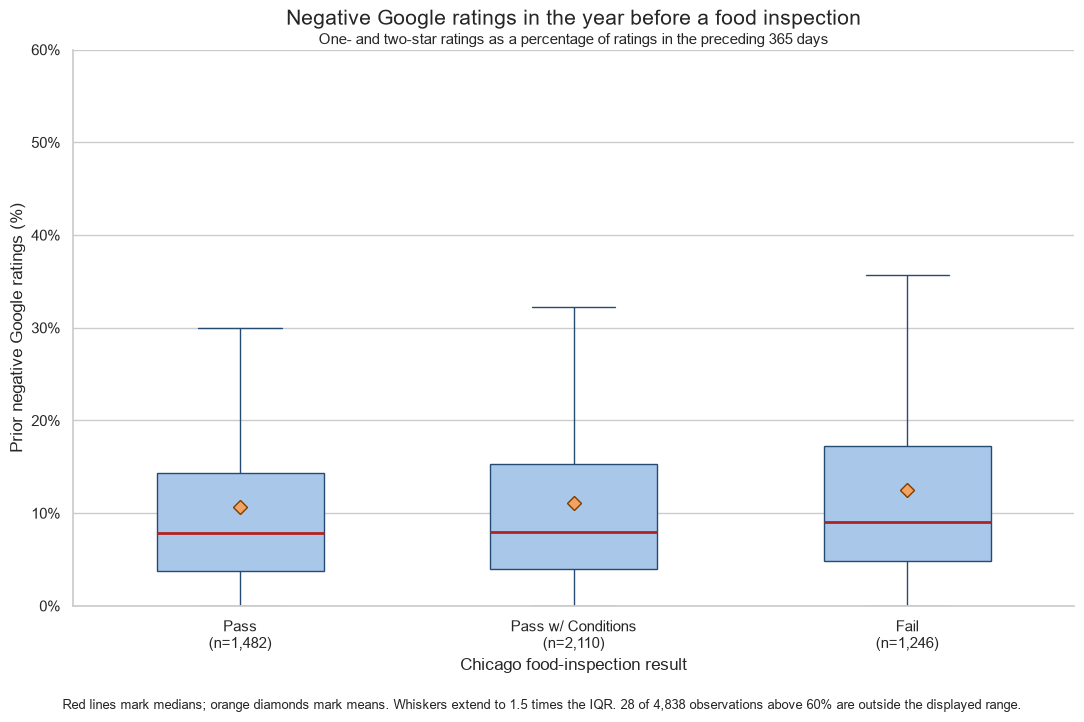

In [13]:
above_display_range = int(
    (inspection_events["negative_review_percentage"] > 60).sum()
)

fig, ax = plt.subplots(figsize=(11, 7))
sns.boxplot(
    data=inspection_events,
    x="results",
    y="negative_review_percentage",
    order=result_order,
    width=0.5,
    showfliers=False,
    showmeans=True,
    boxprops={"facecolor": "#A9C7E8", "edgecolor": "#264B73"},
    medianprops={"color": "#B22222", "linewidth": 2},
    whiskerprops={"color": "#264B73"},
    capprops={"color": "#264B73"},
    meanprops={
        "marker": "D",
        "markerfacecolor": "#F4A261",
        "markeredgecolor": "#7A3E00",
        "markersize": 7,
    },
    ax=ax,
)

sample_sizes = inspection_summary["restaurants"].astype(int).to_dict()
ax.set_xticklabels(
    [f"{result}\n(n={sample_sizes[result]:,})" for result in result_order],
    fontsize=11,
)
ax.set_title(
    "Negative Google ratings in the year before a food inspection",
    fontsize=15,
    pad=18,
)
ax.text(
    0.5,
    1.01,
    "One- and two-star ratings as a percentage of ratings in the preceding 365 days",
    transform=ax.transAxes,
    ha="center",
    fontsize=11,
)
ax.set_xlabel("Chicago food-inspection result", fontsize=12)
ax.set_ylabel("Prior negative Google ratings (%)", fontsize=12)
ax.set_ylim(0, 60)
ax.set_yticks(np.arange(0, 61, 10))
ax.set_yticklabels([f"{value}%" for value in range(0, 61, 10)])
ax.grid(axis="x", visible=False)
sns.despine(ax=ax)
fig.text(
    0.5,
    -0.025,
    (
        "Red lines mark medians; orange diamonds mark means. Whiskers extend to 1.5 times the IQR. "
        f"{above_display_range:,} of {len(inspection_events):,} observations above 60% are outside the displayed range."
    ),
    ha="center",
    fontsize=9.5,
)
plt.tight_layout()
plt.show()

### So what?

With this box-plot were able observe that restaurants that failed an inspection had a slightly higher share of negative Google ratings during the preceding year. The failed group averaged **12.5%** negative ratings with a **9.1%** median, compared with **10.6%** and **7.9%** among restaurants that passed. Restaurants passing with conditions fell between them by mean **11.1%** and had a median of **7.9%**. All three distributions are right-skewed and overlap substantially.

This result was expected because poor restaurant cleanliness, food handling, and service condtions could affect both customer ratings and the afformentioned health inspections by Chicago authorities. However, the size of the differences were smaller than expected.

Failed inspections were only associated with only about 1.9 percentage points more negative ratins on average than a passing result. This suggests that ratings online may contain valid signals about an establisment's operational problems but are not strong enough to stand alone as an inspection to risk indicator. Written reviews mentioning these operational problems regaring cleanliness or safety maybe more accurate than star or numeric ratings alone.

This is an association, not evidence that negative reviews cause a direct inspection failiure. Things like restaurant type, location, price, review amount and inspection categories could affect both of these variables. Also linkage error could be very unlikely but possible beacuse Google and Chicago food-inspections lack a common identifier for each establisment, but since geograpic and name variables vere used as thresholds the linkage is error is very unlikely.

